In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
DATA_PATH = Path("2026-09-01.parquet")
parquet = pq.ParquetFile(DATA_PATH)


In [4]:
parquet

In [6]:
schema = pd.DataFrame([
    {"column": field.name, "arrow_type": str(field.type),
     "original_path": (field.metadata or {}).get(b"path", b"").decode()}
    for field in parquet.schema_arrow
])

In [7]:
schema

,column,arrow_type,original_path
0,timestamp,timestamp[ms],timestamp
1,yearmonth,string,yearmonth
2,_id,string,_id
3,intersection_id,string,intersection.id
4,intersection_type,null,intersection.type
5,sourceId,string,sourceId
6,incomingLink_id,string,incomingLink.id
7,incomingLink_type,null,incomingLink.type
8,incomingLink_lane,null,incomingLink.lane
9,crossingDuration,int64,crossingDuration


In [9]:
columns = [f.name for f in parquet.schema_arrow if f.name != "movements"]

df = pd.read_parquet(DATA_PATH, columns=columns, dtype_backend="pyarrow")


In [10]:
df.describe()

,timestamp,crossingDuration,version,requestTimestamp,reliability,creationTimestamp,messageExpiryInterval
count,1495678,1450678.0,1495678.0,1495678.0,1495678.0,1495678.0,1495678.0
mean,2026-09-01 15:45:57.975000,64.060391,1788274779253.785645,1788274787643.35376,11.846841,1788274775369.785889,8.211354
min,2026-09-01 00:00:00.101000,0.0,1787556884873.0,1787556914873.0,10.0,1787556884873.0,0.0
25%,2026-09-01 12:38:42.634000,0.0,1788266239892.0,1788266244781.25,10.0,1788266235042.0,0.0
50%,2026-09-01 16:39:54.975000,0.0,1788280728961.5,1788280736414.5,10.0,1788280725238.5,0.0
75%,2026-09-01 20:21:40.750000,0.0,1788294071109.0,1788294080302.5,10.0,1788294067451.0,17.0
max,2026-09-01 23:59:59.933000,3000.0,1788307199932.0,1788307368154.0,100.0,1788307199932.0,59.0
std,NaN,433.679109,49307513.595676,49306175.714478,12.759507,49307127.320576,11.743515


In [15]:
len(df['requestTimestamp'].unique())

997657

In [17]:
df['requestTimestamp'].unique()

<ArrowExtensionArray>
[1788220799461, 1788220818117, 1788220770019, 1788220800204, 1788220800272,
 1788220800372, 1788220800446, 1788220800555, 1788220813581, 1788220800616,
 ...
 1788307198761, 1788307210798, 1788307206994, 1788307199447, 1788307224405,
 1788307211407, 1788307199691, 1788307199866, 1788307211918, 1788307212932]
Length: 997657, dtype: int64[pyarrow]

## Detections for one junction
Change `junction_id` to select a junction. Each row counts as one detection record, including repeated request updates.

In [18]:
junction_id = "bridge.high_14"

junction = df[df["intersection_id"] == junction_id].copy()
junction["timestamp"] = pd.to_datetime(junction["timestamp"])

print(f"Detections at {junction_id}: {len(junction):,}")

# Count detection records in each hour.
hourly_detections = junction.set_index("timestamp").resample("h").size()
hourly_detections

Detections at bridge.high_14: 203,847


timestamp
2026-09-01 00:00:00     8607
2026-09-01 01:00:00     4135
2026-09-01 02:00:00     2597
2026-09-01 03:00:00     1264
2026-09-01 04:00:00      603
2026-09-01 05:00:00      381
2026-09-01 06:00:00      363
2026-09-01 07:00:00      333
2026-09-01 08:00:00      713
2026-09-01 09:00:00     1890
2026-09-01 10:00:00     5470
2026-09-01 11:00:00    12557
2026-09-01 12:00:00    15439
2026-09-01 13:00:00    11705
2026-09-01 14:00:00    10849
2026-09-01 15:00:00    12765
2026-09-01 16:00:00    14222
2026-09-01 17:00:00    13212
2026-09-01 18:00:00    13205
2026-09-01 19:00:00    14102
2026-09-01 20:00:00    17365
2026-09-01 21:00:00    17612
2026-09-01 22:00:00    13241
2026-09-01 23:00:00    11217
Freq: h, dtype: int64

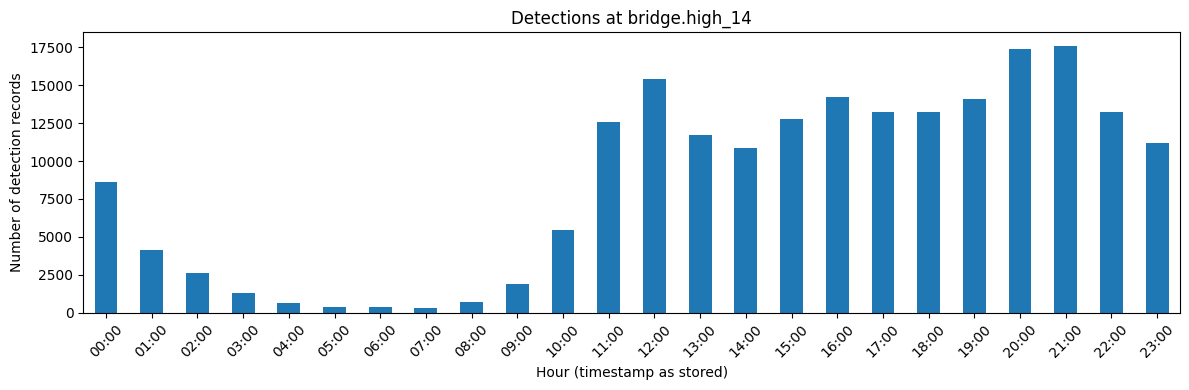

In [19]:
hourly_detections.plot(kind="bar", figsize=(12, 4))
plt.title(f"Detections at {junction_id}")
plt.xlabel("Hour (timestamp as stored)")
plt.ylabel("Number of detection records")
plt.xticks(range(len(hourly_detections)), hourly_detections.index.strftime("%H:%M"), rotation=45)
plt.tight_layout()
plt.show()

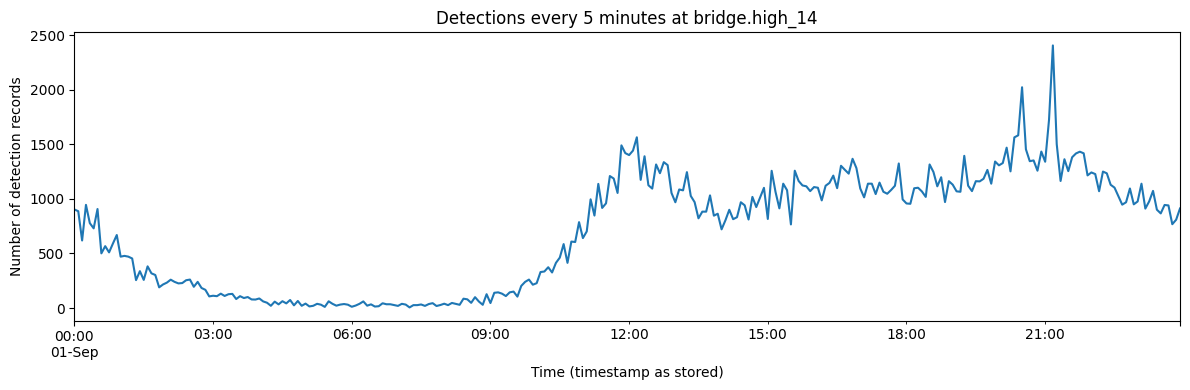

In [20]:
# Line plot for the junction selected above.
junction.set_index("timestamp").resample("5min").size().plot(
    kind="line", figsize=(12, 4)
)
plt.title(f"Detections every 5 minutes at {junction_id}")
plt.xlabel("Time (timestamp as stored)")
plt.ylabel("Number of detection records")
plt.tight_layout()
plt.show()

In [21]:
# Personalize these settings.
selected_junction = "bridge.high_14"
selected_timestamp = "2026-09-01 12:00:00"
window_seconds = 60  # Look forward 60 seconds; use 0 for an exact timestamp.
sensor_id = None  # Paste a sourceId from the list below; None includes all sensors.

records = df[df["intersection_id"] == selected_junction].copy()
records["timestamp"] = pd.to_datetime(records["timestamp"])
print("Available sensor IDs (sourceId):")
print(records["sourceId"].dropna().unique().tolist())

# Use the stored timestamp clock; no timezone conversion.
start = pd.Timestamp(selected_timestamp)
if window_seconds == 0:
    matches = records[records["timestamp"] == start]
else:
    end = start + pd.Timedelta(seconds=window_seconds)
    matches = records[(records["timestamp"] >= start) & (records["timestamp"] < end)]

if sensor_id is not None:
    matches = matches[matches["sourceId"] == sensor_id]

print(f"Matching detection records: {len(matches):,}")
display(matches.sort_values("timestamp"))

Available sensor IDs (sourceId):
['REMOTE_SENSOR-bridge.high_14-fc_du_161.riverside_w820429', 'SENSOR-bridge.high_14-fc_du_bridge.high_se1978-3913069', 'SENSOR-bridge.high_14-fc_du_bridge.high_ne65502-3913080', 'SENSOR-bridge.high_14-fc_du_bridge.high_nw8634-3913083', 'SENSOR-bridge.franklin_23-fc_du_bridge.franklin_sw316762-3913019', 'REMOTE_SENSOR-bridge.high_14-fc_du_161.riverside_w820432', 'SENSOR-bridge.high_14-fc_du_bridge.high_nw8637-3913126', 'SENSOR-high.rock_15-fc_du_high.rock_sw34451-3913072', 'SENSOR-bridge.high_14-fc_du_bridge.high_nw8640-3913147', 'REMOTE_SENSOR-bridge.high_14-fc_du_161.riverside_w820433', 'SENSOR-bridge.high_14-fc_du_bridge.high_se1981-3913152', 'SENSOR-bridge.high_14-fc_du_bridge.high_nw8645-3913161', 'SENSOR-bridge.high_14-fc_du_bridge.high_se1982-3913174', 'SENSOR-bridge.high_14-fc_du_bridge.high_sw34308-3913188', 'SENSOR-high.rock_15-fc_du_high.rock_sw34458-3913185', 'SENSOR-bridge.high_14-fc_du_bridge.high_ne65502-3913199', 'SENSOR-bridge.franklin_2

,timestamp,yearmonth,_id,intersection_id,intersection_type,sourceId,incomingLink_id,incomingLink_type,incomingLink_lane,crossingDuration,...,onBehalfOf_id,onBehalfOf_type,onBehalfOf_modality,id,entryZone,source,reliability,stuck,creationTimestamp,messageExpiryInterval
295100,2026-09-01 12:00:00.551,202609,6a96be432140b8ca87f34bfe,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3466928,None,CAR,crossing-Vehicle-5925606,<NA>,REMOTE_SENSOR,10,False,1788263999914,17
295101,2026-09-01 12:00:00.551,202609,6a96be432140b8ca87f34bff,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3466906,None,CAR,crossing-Vehicle-5925568,<NA>,REMOTE_SENSOR,10,False,1788263997885,17
295108,2026-09-01 12:00:00.925,202609,6a96be432140b8ca87f34c06,bridge.high_14,None,SENSOR-bridge.franklin_23-fc_du_bridge.frankli...,23.14,None,None,0,...,Vehicle-3466417,None,CAR,crossing-Vehicle-5925620,<NA>,SENSOR,10,False,1788264000921,7
295114,2026-09-01 12:00:01.200,202609,6a96be432140b8ca87f34c0c,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3466928,None,CAR,crossing-Vehicle-5925606,<NA>,REMOTE_SENSOR,10,False,1788263999914,17
295115,2026-09-01 12:00:01.200,202609,6a96be432140b8ca87f34c0d,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3466906,None,CAR,crossing-Vehicle-5925568,<NA>,REMOTE_SENSOR,10,False,1788263997885,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297019,2026-09-01 12:00:58.020,202609,6a96be7f2140b8ca87f37a31,bridge.high_14,None,SENSOR-bridge.high_14-fc_du_bridge.high_ne1001...,bridge.high_14_w02,None,None,<NA>,...,Pedestrian-236405,None,PEDESTRIAN,crossing-Pedestrian-236405,<NA>,SENSOR,10,False,1788264057995,0
297020,2026-09-01 12:00:58.020,202609,6a96be7f2140b8ca87f37a32,bridge.high_14,None,SENSOR-bridge.high_14-fc_du_bridge.high_ne1001...,bridge.high_14_w02,None,None,<NA>,...,Pedestrian-236406,None,PEDESTRIAN,crossing-Pedestrian-236406,<NA>,SENSOR,10,False,1788264057995,0
297022,2026-09-01 12:00:58.128,202609,6a96be7f2140b8ca87f37a34,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3467434,None,CAR,crossing-Vehicle-5926572,<NA>,REMOTE_SENSOR,10,False,1788264055699,17
297044,2026-09-01 12:00:59.194,202609,6a96be7f2140b8ca87f37a4a,bridge.high_14,None,REMOTE_SENSOR-bridge.high_14-fc_du_161.riversi...,east.14,None,None,0,...,Vehicle-3467434,None,CAR,crossing-Vehicle-5926572,<NA>,REMOTE_SENSOR,10,False,1788264055699,17


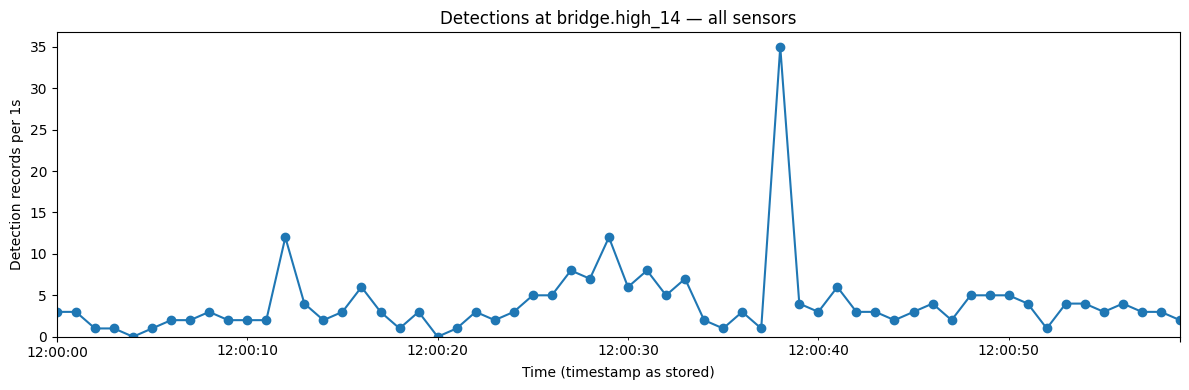

In [22]:
# Plot the filtered records from the previous cell.
plot_interval = "1s"  # Change to "1min" for longer time windows.

if matches.empty:
    print("No matching detections. Adjust the filters in the previous cell.")
else:
    counts = matches.set_index("timestamp").resample(plot_interval).size()
    counts.plot(kind="line", marker="o", figsize=(12, 4))
    plt.title(f"Detections at {selected_junction} — {sensor_id or 'all sensors'}")
    plt.xlabel("Time (timestamp as stored)")
    plt.ylabel(f"Detection records per {plot_interval}")
    plt.ylim(bottom=0)
    plt.tight_layout()
    plt.show()
